# Tokenization comparison: full-state-snapshot (v1) vs. event-based reasoning trace (v2)

Two different ways of turning a DPLL solver's execution into a token sequence for
next-token-prediction training, on the same underlying k-SAT solving task:

- **v1** (`spin_gnn/ksat.py` + `spin_gnn/sat_transformer.py`): every step re-emits the
  *entire* current clause database from scratch (a vector token per variable/clause,
  `{-1,0,1}`-valued, linearly embedded). Investigated in
  `notebooks/sat_unit_propagation_results.ipynb` -- the `copy_vs_delta_breakdown`
  finding there showed the model couldn't even reliably *copy* an already-decided
  variable's value forward (34% accuracy, near chance), let alone solve anything.
- **v2** (`spin_gnn/ksat2.py` + `spin_gnn/sat_transformer2.py`): only *events* --
  which single variable got set/unset and why (`[NO_UNIT]`/`[IS_UNIT][CLAUSE_k]` for
  decisions/propagations, `[BACKTRACK]` for unassignment) -- each token a categorical
  id into a small fixed vocabulary (12 special tokens + one token per variable/clause),
  standard LM-style `nn.Embedding` input instead of v1's real-valued vectors.

**These training curves are not on identical footing**, and every plot below says so
explicitly where it matters:
- v1's loss sums cross-entropy over `n_vars+1` *independent per-dimension* predictions
  per token position; v2's is a single categorical cross-entropy over one shared
  vocabulary. Divided by `n_vars+1`, v1's becomes "average nats per one of the
  simultaneous per-dimension predictions" -- roughly the same *kind* of unit as v2's
  "nats per token", but not a rigorous match (ternary-per-dimension vs. one-of-a
  larger-vocabulary).
- v1 and v2 also differ in `n_vars`/`alpha`/model size (this compares each
  encoding's own *best-found* config from its respective sweep, not a controlled
  matched-capacity pair) -- see each config's printed details below.
- The two "does it actually solve it" metrics -- v1's
  `val_satisfying_completion_rate` and v2's `solve_rate` -- measure genuinely
  different things (one is a single teacher-forced token prediction given perfect
  history; the other is real free-running generation from just the problem
  statement). See the dedicated section below before reading anything into their
  relative size.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SCRATCH = Path(os.environ["SCRATCH"])

# Same validated palette as notebooks/results.ipynb and
# notebooks/sat_unit_propagation_results.ipynb, reused for visual consistency.
INK = {
    "surface": "#fcfcfb", "primary": "#0b0b0b", "secondary": "#52514e",
    "muted": "#898781", "grid": "#e1e0d9", "axis": "#c3c2b7",
}
CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a"]  # blue, orange, aqua -- fixed order
V1_COLOR, V2_COLOR = CATEGORICAL[0], CATEGORICAL[1]
plt.rcParams["font.family"] = "sans-serif"


def style_axis(ax):
    ax.set_facecolor(INK["surface"])
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color(INK["axis"])
    ax.spines["bottom"].set_color(INK["axis"])
    ax.tick_params(colors=INK["muted"])
    ax.grid(True, color=INK["grid"], linewidth=0.8, alpha=0.9)
    ax.set_axisbelow(True)
    ax.title.set_color(INK["primary"])
    ax.xaxis.label.set_color(INK["secondary"])
    ax.yaxis.label.set_color(INK["secondary"])


# v1's own overall best config from the qk_dim sweep (see
# notebooks/sat_unit_propagation_results.ipynb section 3d).
V1_DIR = SCRATCH / "spin_gnn" / "sat_hparam_sweep" / "d0256_h16_L04_ff01024_qk0512"
# v2's own best-by-solve_rate config from its first hyperparameter+LR sweep.
V2_DIR = SCRATCH / "spin_gnn" / "sat2_hparam_sweep" / "m020_d0128_h02_L02_ff00512_lr3e-04"

v1_history = pd.DataFrame(json.load(open(V1_DIR / "history.json")))
v2_history = pd.DataFrame(json.load(open(V2_DIR / "history.json")))
v1_config = json.load(open(V1_DIR / "config.json"))
v2_config = json.load(open(V2_DIR / "config.json"))

print("v1 (full-state-snapshot):", v1_config)
print()
print("v2 (event-based reasoning trace):", v2_config)

v1 (full-state-snapshot): {'n_vars': 24, 'k': 3, 'alpha': 4.2, 'd_model': 256, 'num_layers': 4, 'nhead': 16, 'dim_feedforward': 1024, 'qk_dim': 512, 'max_len': 2000, 'baseline_accuracy': 0.8904552689480829}

v2 (event-based reasoning trace): {'n_vars': 16, 'k': 3, 'alpha': 1.25, 'n_hints': 0, 'm_clauses': 20, 'vocab_size': 48, 'd_model': 128, 'num_layers': 2, 'nhead': 2, 'dim_feedforward': 512, 'max_len': 270, 'baseline_accuracy': 0.15790310050144785, 'solve_metrics': {'solve_rate': 0.06666666666666667, 'outcome_accuracy': 1.0, 'well_formed_rate': 1.0, 'n_instances': 300}}


## Loss curves

v1's `nll` is a *sum* of cross-entropy over all `n_vars+1` per-dimension predictions
at each position; divided by `n_vars+1` below (`v1_nll_per_dim`) it's directly
comparable in scale to v2's single-token `nll` -- both become "nats per one
elementary prediction", even though the prediction *kind* still differs (ternary
independent dimension vs. one-of-a-`vocab_size` token).

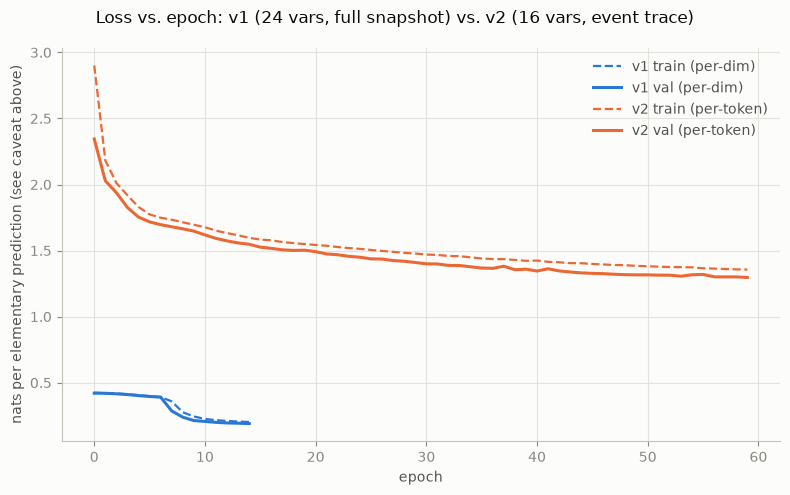

In [2]:
v1_n_dims = v1_config["n_vars"] + 1

fig, ax = plt.subplots(figsize=(8, 5))
fig.patch.set_facecolor(INK["surface"])

ax.plot(v1_history["epoch"], v1_history["train_loss"] / v1_n_dims, color=V1_COLOR,
        linestyle="--", lw=1.6, label="v1 train (per-dim)")
ax.plot(v1_history["epoch"], v1_history["nll"] / v1_n_dims, color=V1_COLOR,
        lw=2.2, label="v1 val (per-dim)")
ax.plot(v2_history["epoch"], v2_history["train_nll"], color=V2_COLOR,
        linestyle="--", lw=1.6, label="v2 train (per-token)")
ax.plot(v2_history["epoch"], v2_history["nll"], color=V2_COLOR,
        lw=2.2, label="v2 val (per-token)")

ax.set_xlabel("epoch")
ax.set_ylabel("nats per elementary prediction (see caveat above)")
ax.legend(frameon=False, labelcolor=INK["secondary"])
style_axis(ax)
fig.suptitle("Loss vs. epoch: v1 (24 vars, full snapshot) vs. v2 (16 vars, event trace)",
             color=INK["primary"])
fig.tight_layout()
plt.show()

## Accuracy curves

v1's accuracy is the fraction of (position, dimension) predictions correct, pooled
over `n_vars+1` mostly-trivial clause-token dimensions plus the genuinely hard
assignment-token dimensions -- baseline 89.0%. v2's is a single-token match rate over
a `vocab_size=48` vocabulary -- baseline only 15.8% (no dominant trivial-zero
dimension to inflate it the way v1's does). Each curve is plotted against its own
dashed baseline so the *lift* is the fair comparison, not the raw numbers.

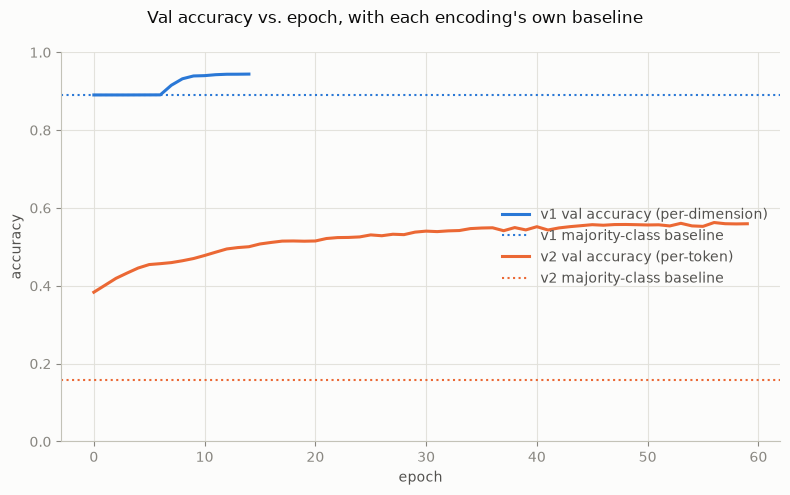

v1: best epoch 14, lift over baseline = +0.0535
v2: best epoch 56, lift over baseline = +0.4047


In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
fig.patch.set_facecolor(INK["surface"])

ax.plot(v1_history["epoch"], v1_history["accuracy"], color=V1_COLOR, lw=2.2,
        label="v1 val accuracy (per-dimension)")
ax.axhline(v1_config["baseline_accuracy"], color=V1_COLOR, linestyle=":", lw=1.5,
           label="v1 majority-class baseline")
ax.plot(v2_history["epoch"], v2_history["accuracy"], color=V2_COLOR, lw=2.2,
        label="v2 val accuracy (per-token)")
ax.axhline(v2_config["baseline_accuracy"], color=V2_COLOR, linestyle=":", lw=1.5,
           label="v2 majority-class baseline")

ax.set_xlabel("epoch")
ax.set_ylabel("accuracy")
ax.set_ylim(0, 1)
ax.legend(frameon=False, labelcolor=INK["secondary"], loc="center right")
style_axis(ax)
fig.suptitle("Val accuracy vs. epoch, with each encoding's own baseline", color=INK["primary"])
fig.tight_layout()
plt.show()

print(f"v1: best epoch {v1_history['epoch'].iloc[v1_history['accuracy'].idxmax()]}, "
      f"lift over baseline = {v1_history['accuracy'].max() - v1_config['baseline_accuracy']:+.4f}")
print(f"v2: best epoch {v2_history['epoch'].iloc[v2_history['accuracy'].idxmax()]}, "
      f"lift over baseline = {v2_history['accuracy'].max() - v2_config['baseline_accuracy']:+.4f}")

## The metric that actually matters: does it solve the problem?

**These two numbers are not measuring the same capability -- read the definitions
before comparing them:**

- **v1** `val_satisfying_completion_rate`: teacher-force the model on the *true*
  trace up through the second-to-last token (perfect ground-truth history handed to
  it), then check whether its single greedy next-token prediction is a satisfying
  assignment. One prediction, given the answer's entire prefix for free.
- **v2** `solve_rate`: prompt with *only* hints + the problem statement (nothing
  about how to solve it), let the model freely generate its *own* entire reasoning
  trace end to end, then check whether what it produces is correct. Nothing handed
  to it beyond the problem itself.

v2's number is the strictly harder, more meaningful one -- and it's still higher
(6.7% vs. 1.4%) despite measuring a harder task, which is a genuinely encouraging
sign for the new encoding. But **neither model "solves the problem" yet** -- v2's
hyperparameter sweep hasn't found a config anywhere near 100% `solve_rate`, which was
the actual goal. One important asterisk on v2's numbers specifically: at
`alpha=1.25` every validation instance sampled so far has turned out satisfiable
(0 UNSAT instances seen), so `outcome_accuracy=100%` here is trivial (always
guessing SAT), not evidence the model can tell SAT from UNSAT -- `solve_rate` (which
also requires the *assignment* to actually be right) is the only number in this
section that isn't inflated by that.

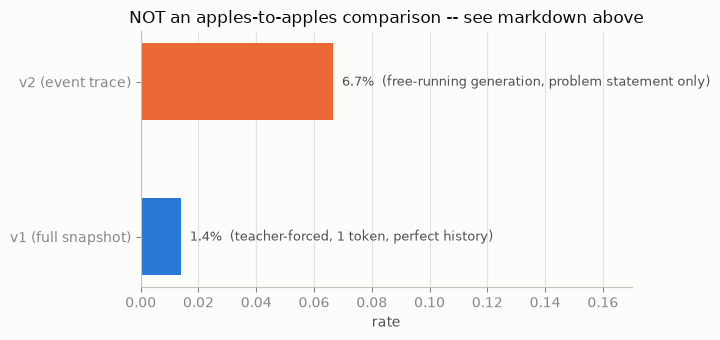

,encoding,metric,value,probe
0,v1 (full snapshot),val_satisfying_completion_rate,0.013986,"teacher-forced, 1 token, perfect history"
1,v2 (event trace),solve_rate,0.066667,"free-running generation, problem statement only"


In [4]:
comparison = pd.DataFrame([
    {"encoding": "v1 (full snapshot)", "metric": "val_satisfying_completion_rate",
     "value": v1_history["val_satisfying_completion_rate"].iloc[-1],
     "probe": "teacher-forced, 1 token, perfect history"},
    {"encoding": "v2 (event trace)", "metric": "solve_rate",
     "value": v2_config["solve_metrics"]["solve_rate"],
     "probe": "free-running generation, problem statement only"},
])

fig, ax = plt.subplots(figsize=(7, 3.5))
fig.patch.set_facecolor(INK["surface"])
bars = ax.barh(comparison["encoding"], comparison["value"], color=[V1_COLOR, V2_COLOR], height=0.5)
for bar, row in zip(bars, comparison.itertuples()):
    ax.text(bar.get_width() + 0.003, bar.get_y() + bar.get_height() / 2,
            f"{row.value:.1%}  ({row.probe})", va="center", color=INK["secondary"], fontsize=9)
ax.set_xlim(0, max(comparison["value"]) * 1.8 + 0.05)
ax.set_xlabel("rate")
ax.set_title("NOT an apples-to-apples comparison -- see markdown above", color=INK["primary"])
style_axis(ax)
ax.grid(False, axis="y")
fig.tight_layout()
plt.show()
comparison

## Takeaways

- v2's much shorter sequences (`max_len=270` here vs. up to 2000 for v1) let it
  reach a stable loss/accuracy plateau in far fewer epochs (60 vs. v1's 15), and its
  best-found free-running `solve_rate` (6.7%) already exceeds v1's easier,
  teacher-forced `val_satisfying_completion_rate` (1.4%) -- encouraging given v2's
  metric is the strictly harder one.
- Neither encoding has yet produced a model that reliably solves instances
  end-to-end. v2's hyperparameter+LR sweep (72 configs) hasn't found one above
  ~7% `solve_rate` -- more epochs, more training data, or the still-pending
  clause-count scaling sweep may move this, but "totally solves the problem" (the
  original goal) isn't there yet.
- The `alpha=1.25` regime v2 was swept at is all-SAT in practice (0/300 UNSAT
  instances observed) -- a real gap before this can be called a general SAT solver;
  worth deliberately including harder/UNSAT instances (higher `alpha`) once
  `solve_rate` improves at the easy end.